# **Homework 4: Evaluation Metrics for Classification**

In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not.

In [1]:
# Import block

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
# Creating the dataframe

df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv', sep = ',')

# df.columns = df.columns.str.lower().str.replace(' ', '_')

df.head() # Shows the first 5 rows of dataset

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isnull().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [4]:
categorical = list(df.select_dtypes(include='object').columns)
numerical = [c for c in df.columns if c not in categorical + ['converted']]
print('categorical:', categorical)
print('numerical:  ', numerical)

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


np.int64(0)

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

print(len(df_train), len(df_val), len(df_test))

3000 1000 1000


### **Question 1**
ROC AUC feature importance

*Use each numerical variable as a score on the training set; if AUC < 0.5, negate it.*

In [6]:
q1 = {}
for col in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    q1[col] = auc
    print(f'{col:26s} {auc:.4f}')

print('\nHighest AUC:', max(q1, key=q1.get))

lead_score                 0.7882
number_of_courses_viewed   0.7230
interaction_count          0.7649
annual_income              0.6082

Highest AUC: lead_score


### **Question 2**
Training the model

In [7]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred)
print('Validation AUC:', round(auc_val, 3))

Validation AUC: 0.732


### **Question 3**
Precision and Recall

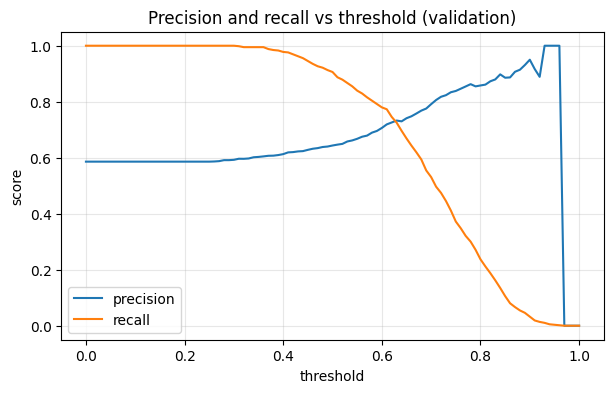

In [8]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
rows = []
for t in thresholds:
    actual_pos = (y_val == 1)
    pred_pos = (y_pred >= t)
    tp = (pred_pos & actual_pos).sum()
    fp = (pred_pos & ~actual_pos).sum()
    fn = (~pred_pos & actual_pos).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((t, tp, fp, fn, p, r))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.ylabel('score'); plt.legend(); plt.grid(alpha=0.3)
plt.title('Precision and recall vs threshold (validation)')
plt.show()

In [9]:
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['abs_diff'] = (valid.precision - valid.recall).abs()
best_q3 = valid.loc[valid.abs_diff.idxmin()]
print(best_q3[['threshold', 'precision', 'recall', 'abs_diff']])
print('\nIntersection threshold:', best_q3.threshold)

threshold    0.630000
precision    0.732759
recall       0.725256
abs_diff     0.007503
Name: 63, dtype: float64

Intersection threshold: 0.63


### **Question 4**
F1-Score

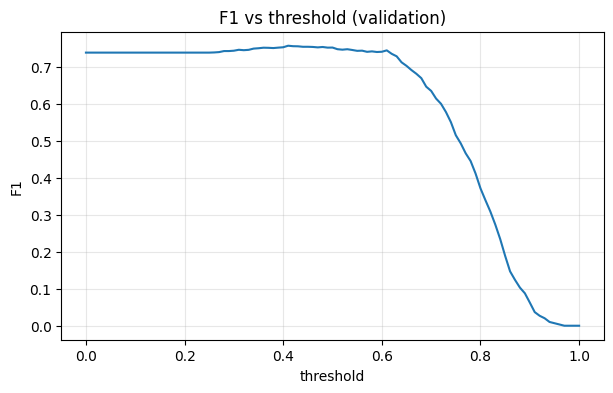

Max F1 = 0.7576 at threshold 0.41


In [10]:
p, r = df_scores.precision, df_scores.recall
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r), 0.0)

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.grid(alpha=0.3)
plt.title('F1 vs threshold (validation)')
plt.show()

best_q4 = df_scores.loc[df_scores.f1.idxmax()]
print('Max F1 = %.4f at threshold %.2f' % (best_q4.f1, best_q4.threshold))

###**Question 5**
5-Fold CV

In [11]:
def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    dicts = df_[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]
    dv_k, model_k = train(df_tr, df_tr.converted.values, C=1.0)
    y_p = predict(df_va, dv_k, model_k)
    scores.append(roc_auc_score(df_va.converted.values, y_p))

print('fold AUCs:', np.round(scores, 4))
print('mean = %.3f, std = %.3f' % (np.mean(scores), np.std(scores)))

fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
mean = 0.732, std = 0.007


###**Question 6**
Hyperparameter tuning


In [12]:
results = []
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    sc = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv_k, model_k = train(df_tr, df_tr.converted.values, C=C)
        y_p = predict(df_va, dv_k, model_k)
        sc.append(roc_auc_score(df_va.converted.values, y_p))
    results.append((C, round(np.mean(sc), 3), round(np.std(sc), 3)))
    print('C=%-8s mean=%.3f std=%.3f' % (C, np.mean(sc), np.std(sc)))

# best mean; ties -> lowest std; still tied -> smallest C
best_C = sorted(results, key=lambda x: (-x[1], x[2], x[0]))[0][0]
print('\nBest C:', best_C)

C=1e-06    mean=0.617 std=0.019
C=0.001    mean=0.749 std=0.010
C=1        mean=0.732 std=0.007

Best C: 0.001
